In [1]:
import numpy as np
import pandas as pd
from scipy.spatial.distance import cdist
import matplotlib.pyplot as plt

crime_df = pd.read_csv("USArrests.csv")
crime_df.head()


,State,Murder,Assault,UrbanPop,Rape
0,Alabama,13.2,236,58,21.2
1,Alaska,10.0,263,48,44.5
2,Arizona,8.1,294,80,31.0
3,Arkansas,8.8,190,50,19.5
4,California,9.0,276,91,40.6


# Clustering

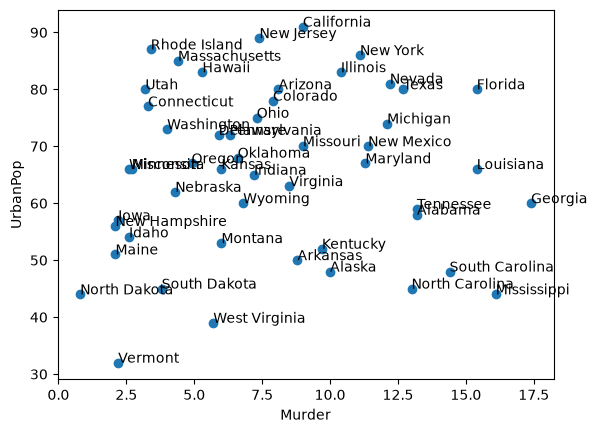

In [3]:
from sklearn.cluster import KMeans

X = crime_df.drop('State', axis=1)
y = crime_df['State']

plt.scatter(X['Murder'], X['UrbanPop'])

# enumerating allows us to keep track 
# of the indexes associated with each iteration
for i, txt in enumerate(y):
    plt.annotate(txt, (X['Murder'][i], X['UrbanPop'][i]))
plt.xlabel('Murder')
plt.ylabel('UrbanPop')
plt.show()

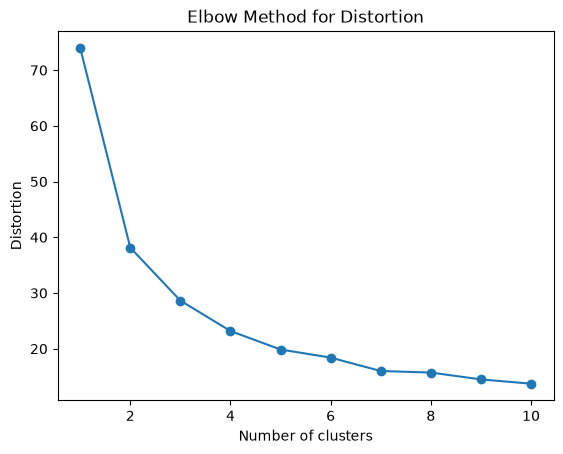

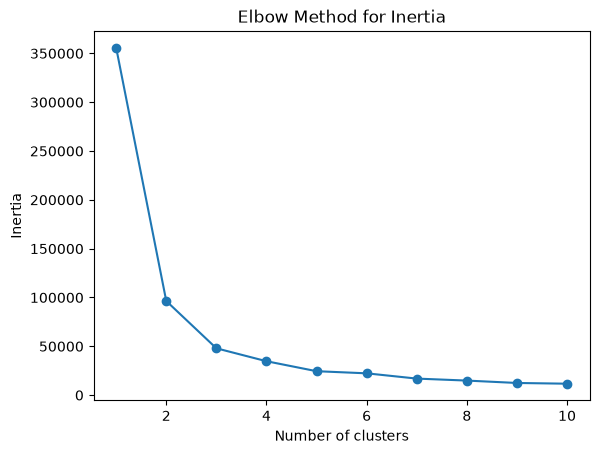

In [5]:
inertias = []
distortions = []

for k in range(1, 11):
    #build a fit the model
    model = KMeans(n_clusters=k, random_state=10).fit(X)

    # distortion is the average of the squared distance from each point to its cluster center
    # (for out purposes, we will be using Euclidean space)
    # Euclidean space = standard 2+ dimensional space
    distance = cdist(X, model.cluster_centers_, 'euclidean')
    distortion = sum(np.min(distance, axis=1))/X.shape[0]
    distortions.append(distortion)

    # inertia is calculated by measuring the distance between each data point
    # and its assigned cluster center, then summing these distances for all points
    # a good model is one with low intertia or distortion AND
    # a low number of clusters is preferred to avoid overfitting
    inertia = model.inertia_
    inertias.append(inertia)

plt.plot(range(1, 11), distortions, marker='o')
plt.title('Elbow Method for Distortion')
plt.xlabel('Number of clusters')
plt.ylabel('Distortion')
plt.show()

plt.plot(range(1, 11), inertias, marker='o')
plt.title('Elbow Method for Inertia')
plt.xlabel('Number of clusters')
plt.ylabel('Inertia')
plt.show()


# Hierarchical 

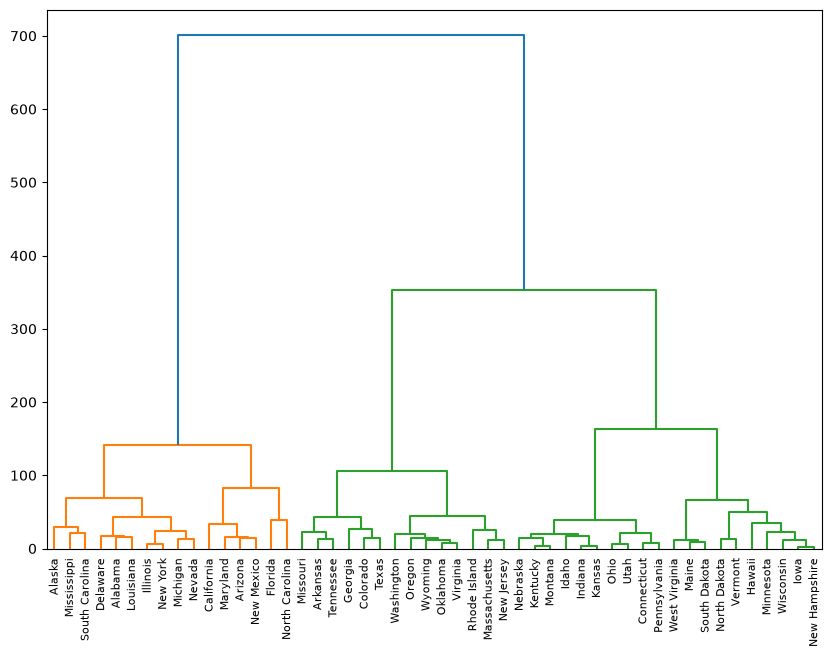

In [6]:
from scipy.cluster.hierarchy import dendrogram, linkage

linked = linkage(X, 'ward')
plt.figure(figsize=(10, 7))

dendro = dendrogram(linked, labels=list(y))



In [8]:
from sklearn.cluster import AgglomerativeClustering
# divides the population into severeal clusters such taht the data points are in the same 
# cluster as other data points that are similar to them.
# those in different clusters are more dissimilar

cluster = AgglomerativeClustering(n_clusters=3, linkage='ward')
labels = cluster.fit_predict(X)
cluster.fit_predict(X)

array([1, 1, 1, 2, 1, 2, 0, 1, 1, 2, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 2, 1,
       0, 1, 2, 0, 0, 1, 0, 2, 1, 1, 1, 0, 0, 2, 2, 0, 2, 1, 0, 2, 2, 0,
       0, 2, 2, 0, 0, 2])

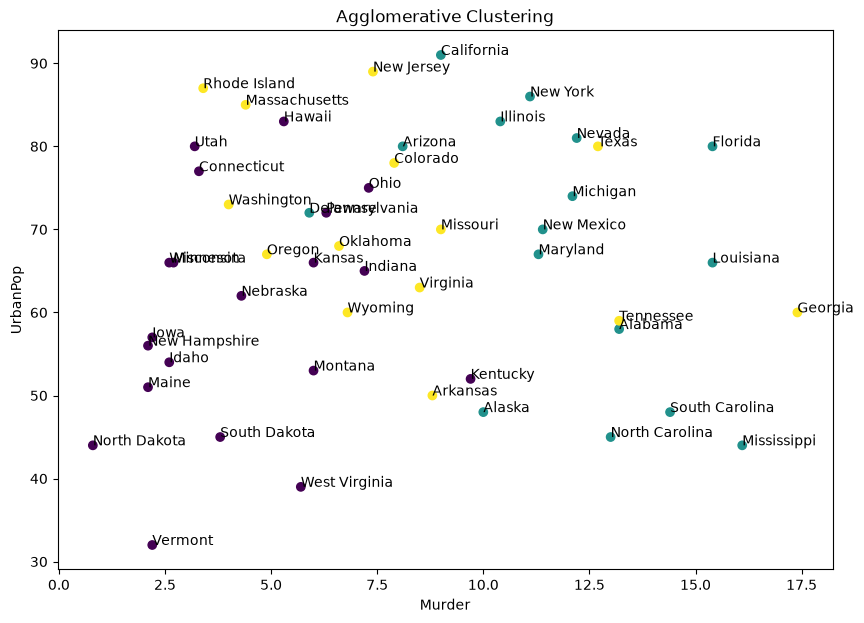

In [9]:
plt.figure(figsize=(10, 7))
plt.scatter(X['Murder'], X['UrbanPop'], c=labels)
for i, txt in enumerate(y):
    plt.annotate(txt, (X['Murder'][i], X['UrbanPop'][i]))
plt.xlabel('Murder')
plt.ylabel('UrbanPop')
plt.title('Agglomerative Clustering')
plt.show()

# Dimensionality Reduction

In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

diabetes_df = pd.read_csv('../week_10/diabetes.csv')
diabetes_df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [14]:
X = diabetes_df.drop('Outcome', axis=1)
y = diabetes_df['Outcome']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=10)

model = LogisticRegression(random_state=10).fit(X_train, y_train)

# predicted outcome
y_predicted = model.predict(X_test)

# calculate recall
from sklearn.metrics import recall_score
recall = recall_score(y_test, y_predicted.round())
recall

/Users/lex/Documents/repos/caps_5001/caps_5001_fall_2026/.my_venv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


0.5084745762711864

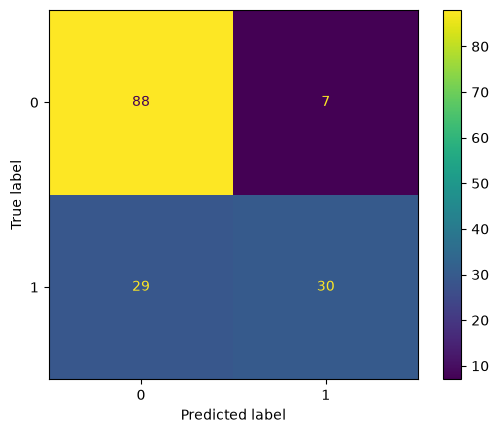

In [15]:
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_estimator(model, X_test, y_test)

In [17]:
from sklearn.decomposition import TruncatedSVD
# singular value decompostion = factorization technique for real or complex numbers in a matrix
# In short, it is untangling patterns in the numbers using matrix decomposition (linear algebra concept)
# trancatedSVD is typically used for dimensionality reduction in sparse matrices (this dataset isnt that)
# it doesnt produce a list of features it is selecting because it is more abstract than that
svd = TruncatedSVD(n_components=6)  # reduce to 6 dimensions
X_train_svd = svd.fit_transform(X_train)
X_test_svd = svd.transform(X_test)

# explained variance ratio tells us how much information (variance) is captured by each of the selected components
svd.explained_variance_ratio_

model = LogisticRegression(random_state=10).fit(X_train_svd, y_train)
y_predicted_svd = model.predict(X_test_svd)
from sklearn.metrics import recall_score
recall_svd = recall_score(y_test, y_predicted_svd.round())
recall_svd

0.4745762711864407